<a href="https://colab.research.google.com/github/charlesanthony1996/explainable-ai-assignment1/blob/main/lab_track_a_backup.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Step 1 - load the uci dataset

In [74]:
!pip install lime numpy pandas torch

In [75]:
import os
import glob
import copy
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

from lime.lime_tabular import LimeTabularExplainer

In [76]:
 # to show wide tables in the terminal
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

seed = 42

np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device("cuda" if torch.cuda.is_available else "cpu")

In [77]:
data_url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
zip_path = "online_retail_ii.zip"

if len(glob.glob("*.xlsx")) == 0:
  print("downloading the dataset...")

  urllib.request.urlretrieve(data_url, zip_path)

  with zipfile.ZipFile(zip_path) as zip_file:
    zip_file.extractall(".")

In [78]:
# find the excel file that came out of the zip
excel_files = glob.glob("*.xlsx")
print(excel_files)

excel_path = excel_files[0]

['online_retail_II.xlsx']


In [79]:
# the excel file has two sheets
sheets = pd.read_excel(excel_path, sheet_name=None)
sheet_names = list(sheets.keys())

print(sheet_names)

first_sheet = sheets[sheet_names[0]]
second_sheet = sheets[sheet_names[1]]

['Year 2009-2010', 'Year 2010-2011']


In [80]:
# remove the overlapping days from the first sheet
second_sheet_start = second_sheet["InvoiceDate"].min()

first_sheet = first_sheet[first_sheet["InvoiceDate"] < second_sheet_start]

raw = pd.concat(
    [first_sheet, second_sheet],
    ignore_index=True
)

print("rows: ", raw.shape[0])
print("From: ", raw["InvoiceDate"].min())
print("To: ", raw["InvoiceDate"].max())


print(raw.head())

rows:  1044848
From:  2009-12-01 07:45:00
To:  2011-12-09 12:50:00
  Invoice StockCode                          Description  Quantity         InvoiceDate  Price  Customer ID         Country
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12 2009-12-01 07:45:00   6.95      13085.0  United Kingdom
1  489434    79323P                   PINK CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0  United Kingdom
2  489434    79323W                  WHITE CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0  United Kingdom
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48 2009-12-01 07:45:00   2.10      13085.0  United Kingdom
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24 2009-12-01 07:45:00   1.25      13085.0  United Kingdom


2. clean the data

keep only real products.
product codes start with 5 digits.
remove rows with price 0 or lower
keep cancellations for now, since they have negative quantites. this affects our net quantity sold per week

In [81]:
data = raw.copy()

data["Invoice"] = data["Invoice"].astype(str)
data["StockCode"] = data["StockCode"].astype(str)

# mark cancelled invoices
data["is_cancellation"] = data["Invoice"].str.startswith("C")

# keep only real products
is_product = data["StockCode"].str.match(r"^\d{5}")
data = data[is_product]

# remove zero or negative prices
data = data[data["Price"] > 0]

print("rows after cleaning: ", data.shape[0])
print("cancelled rows: ", data["is_cancellation"].sum())

rows after cleaning:  1032918
cancelled rows:  17973


In [82]:
# day of the transation (time removed)
data["date"] = data["InvoiceDate"].dt.normalize()

# monday of the week the transaction belongs to
days_since_monday = pd.to_timedelta(data["date"].dt.weekday, unit="D")
# print(days_since_monday)
data["week"] = data["date"] - days_since_monday

print(data[["InvoiceDate", "date", "week"]].head())

          InvoiceDate       date       week
0 2009-12-01 07:45:00 2009-12-01 2009-11-30
1 2009-12-01 07:45:00 2009-12-01 2009-11-30
2 2009-12-01 07:45:00 2009-12-01 2009-11-30
3 2009-12-01 07:45:00 2009-12-01 2009-11-30
4 2009-12-01 07:45:00 2009-12-01 2009-11-30


3. weekly aggregation and input features

we aggregate by week.
daily sales per product are very sparse

the dataset has no promotion or stock columns, so we build proxies


In [83]:
# shop availability : open days per week

In [84]:
open_days = data[["date", "week"]].drop_duplicates()
# print(open_days)

days_open_per_week = open_days.groupby("week")["date"].count()
# print(days_open_per_week)
days_open_per_week = days_open_per_week.rename("days_open")
# print(days_open_per_week)
days_open_per_week = days_open_per_week.reset_index()
# print(days_open_per_week)

print(days_open_per_week.head())
print(days_open_per_week.tail())

        week  days_open
0 2009-11-30          6
1 2009-12-07          6
2 2009-12-14          6
3 2009-12-21          3
4 2010-01-04          6
          week  days_open
99  2011-11-07          6
100 2011-11-14          6
101 2011-11-21          6
102 2011-11-28          6
103 2011-12-05          5


In [85]:
# net quantity per product per week
# sum over all rows, including cancellations (negative quantities here)

weekly_quantity = data.groupby(["StockCode", "week"])["Quantity"].sum()
# print(weekly_quantity.head())

weekly_quantity = weekly_quantity.rename("net_quantity")
# print(weekly_quantity.head())

weekly_quantity = weekly_quantity.reset_index()

print(weekly_quantity.head())

  StockCode       week  net_quantity
0     10002 2009-11-30           141
1     10002 2009-12-07            24
2     10002 2009-12-14            37
3     10002 2009-12-21            14
4     10002 2010-01-04            15


In [86]:
# price and days on sale per product per week

# only real sales (no cancellations).
# the weekly price is the quantity weighted average price : revenue / units

is_sale = (data["is_cancellation"] == False) & (data["Quantity"] > 0)

sales = data[is_sale].copy()

sales["revenue"] = sales["Quantity"] * sales["Price"]

weekly_sales = sales.groupby(["StockCode", "week"]).agg(
    sold_quantity=("Quantity", "sum"),
    revenue=("revenue", "sum"),
    days_on_sale=("date", "nunique")
)

weekly_sales = weekly_sales.reset_index()
print(weekly_sales.head())

weekly_sales["price"] = weekly_sales["revenue"] / weekly_sales["sold_quantity"]

print(weekly_sales.head())

  StockCode       week  sold_quantity  revenue  days_on_sale
0     10002 2009-11-30            141   119.85             4
1     10002 2009-12-07             24    21.25             4
2     10002 2009-12-14             37    32.30             1
3     10002 2009-12-21             14    12.75             3
4     10002 2010-01-04             15    12.75             2
  StockCode       week  sold_quantity  revenue  days_on_sale     price
0     10002 2009-11-30            141   119.85             4  0.850000
1     10002 2009-12-07             24    21.25             4  0.885417
2     10002 2009-12-14             37    32.30             1  0.872973
3     10002 2009-12-21             14    12.75             3  0.910714
4     10002 2010-01-04             15    12.75             2  0.850000


In [87]:
# time split and product selection

# we split by time, never randomly, because we forecast the future

validation_start = pd.Timestamp("2011-04-04")
test_start = pd.Timestamp("2011-07-04")

n_products = 30

train_sales = weekly_sales[weekly_sales["week"] < validation_start]

weeks_per_product = train_sales.groupby("StockCode")["week"].count()
weeks_per_product = weeks_per_product.sort_values(ascending=False)

selected_products = list(weeks_per_product.index[:n_products])
print(len(selected_products))

# product names, for pricing
descriptions = data.drop_duplicates("StockCode")
descriptions = descriptions.set_index("StockCode")["Description"]

for product in selected_products[:10]:
  print(product, "-", descriptions[product], "-", weeks_per_product[product], "weeks")

30
15056N - EDWARDIAN PARASOL NATURAL - 68 weeks
15056BL - EDWARDIAN PARASOL BLACK - 68 weeks
15060B - FAIRY CAKE DESIGN UMBRELLA - 68 weeks
21899 - KEY FOB , GARAGE DESIGN - 68 weeks
21889 - WOODEN BOX OF DOMINOES - 68 weeks
84849B - FAIRY SOAP SOAP HOLDER - 68 weeks
84991 - 60 TEATIME FAIRY CAKE CASES - 68 weeks
21868 - POTTING SHED TEA MUG - 68 weeks
21870 - I CAN ONLY PLEASE ONE PERSON MUG - 68 weeks
21888 - BINGO SET - 68 weeks


In [88]:
# build one row for every product and every week

# weeks with no sales must still exist (but the quantity will be 0)

# the first and last week of the dataset are incomplete, so we drop them

first_week = data["week"].min() + pd.Timedelta(weeks=1)
print(first_week)

last_week = data["week"].max() - pd.Timedelta(weeks=1)
print(last_week)

all_weeks = pd.date_range(first_week, last_week, freq="7D")

print("weeks: ", len(all_weeks))
print("from: ", all_weeks[0].date(), "to", all_weeks[-1].date())

panel_parts = []

for product in selected_products:

  product_frame = pd.DataFrame({"week": all_weeks})
  product_frame["StockCode"] = product

  panel_parts.append(product_frame)

panel = pd.concat(panel_parts, ignore_index=True)

# print(panel.shape)

# add net quantity
panel = panel.merge(
    weekly_quantity,
    on=["StockCode", "week"],
    how="left"
)

# add price and days on sale
panel = panel.merge(
    weekly_sales[["StockCode", "week", "price", "days_on_sale"]],
    on=["StockCode", "week"],
    how="left"
)

# add shop open days
panel = panel.merge(
    days_open_per_week,
    on="week",
    how="left"
)

print(panel.head())

2009-12-07 00:00:00
2011-11-28 00:00:00
weeks:  104
from:  2009-12-07 to 2011-11-28
        week StockCode  net_quantity     price  days_on_sale  days_open
0 2009-12-07    15056N         818.0  3.588142           5.0        6.0
1 2009-12-14    15056N         103.0  5.572816           5.0        6.0
2 2009-12-21    15056N          12.0  5.950000           1.0        3.0
3 2009-12-28    15056N           NaN       NaN           NaN        NaN
4 2010-01-04    15056N         611.0  3.053110           2.0        6.0


  StockCode       week  quantity  price_ratio  promotion  days_on_sale  days_open  month
0   15056BL 2009-12-07     910.0     0.636919          1           6.0        6.0     12
1   15056BL 2009-12-14     238.0     0.877869          1           6.0        6.0     12
2   15056BL 2009-12-21      18.0     1.000000          0           1.0        3.0     12
3   15056BL 2009-12-28       0.0     1.000000          0           0.0        0.0     12
4   15056BL 2010-01-04     912.0     0.618532          1           5.0        6.0      1
5   15056BL 2010-01-11     132.0     0.903005          0           6.0        6.0      1
6   15056BL 2010-01-18      51.0     1.066930          0           4.0        6.0      1
7   15056BL 2010-01-25      17.0     1.000000          0           3.0        6.0      1
8   15056BL 2010-02-01      25.0     1.000000          0           4.0        6.0      2
9   15056BL 2010-02-08      16.0     1.000000          0           5.0        6.0      2


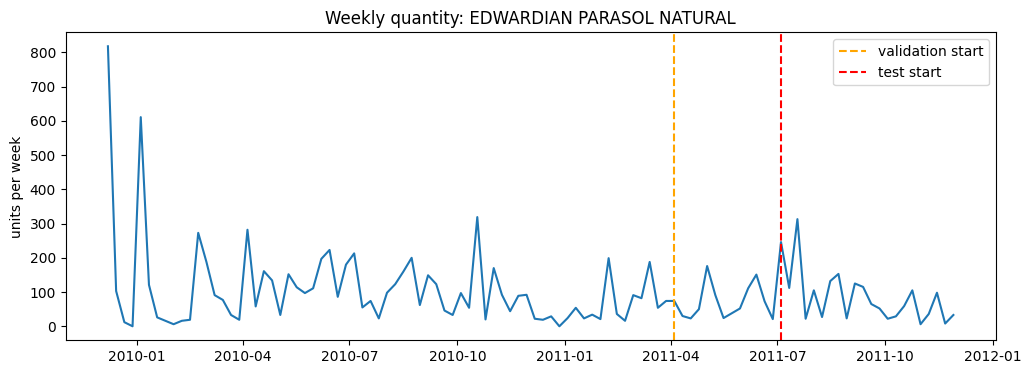

In [91]:
# fill the gaps

# no row -> nothing sold -> quantity 0, days on sale 0
# no row in the shop calendar -> shop closed -> days open 0
# no prce in a week without sales -> use the last know price of that product

panel["quantity"] = panel["net_quantity"].fillna(0)
panel["quantity"] = panel["quantity"].clip(lower=0)

panel["days_on_sale"] = panel["days_on_sale"].fillna(0)
panel["days_open"] = panel["days_open"].fillna(0)

panel = panel.sort_values(["StockCode", "week"])
panel = panel.reset_index(drop=True)

# print(panel.head())

# last known price
panel["price"] = panel.groupby("StockCode")["price"].ffill()
panel["price"] = panel.groupby("StockCode")["price"].bfill()


# usual price = median weekly price of the product? why median?
# training period only (so no information from the test period)

train_panel = panel[panel["week"] < validation_start]

usual_price = train_panel.groupby("StockCode")["price"].median()
# print(usual_price.head())

usual_price = usual_price.rename("usual_price")
usual_price = usual_price.reset_index()

panel = panel.merge(
    usual_price,
    on="StockCode",
    how="left"
)

panel["price_ratio"] = panel["price"] / panel["usual_price"]

panel["promotion"] = (panel["price_ratio"] < 0.9).astype(int)

panel["month"] = panel["week"].dt.month

features = [
    "quantity",
    "price_ratio",
    "promotion",
    "days_on_sale",
    "days_open",
    "month"
]

print(panel[["StockCode", "week"] + features].head(10))

# look at one product over time
example_rows = panel[panel["StockCode"] == selected_products[0]]

plt.figure(figsize=(12, 4))

plt.plot(example_rows["week"], example_rows["quantity"])

plt.axvline(validation_start, color="orange", linestyle="--", label="validation start")
plt.axvline(test_start, color="red", linestyle="--", label="test start")

plt.title("Weekly quantity: " + str(descriptions[selected_products[0]]))
plt.ylabel("units per week")
plt.legend()

plt.show()

4. time windows

each sample has:-

input - the last 8 weeks x 6 features -> shape(8, 6)
target - quantity in the following week

example - weeks 1-8 -> predict week 9, weeks 2-9 -> predict week 10

In [89]:
window = 8

window_list = []
target_list = []
product_list = []
target_week_list = []

for product in selected_products:

  product_rows = panel[panel["StockCode"] == product]
  product_rows = product_rows.sort_values("week")

  feature_values = product_rows[features].to_numpy(dtype=float)
  quantities = product_rows["quantity"].to_numpy(dtype=float)

  weeks = product_rows["weeks"].to_numpy()

  for end in range(window, len(product_rows)):

    window =

